In [ ]:
import os
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# --- CRITICAL: BASE PATH DEFINITION ---
# This is the path to the 'Data' folder containing 'train' and 'test'.
BASE_DIR = '/content/drive/MyDrive/Colab Notebooks/Data'

# --- YOUR REQUESTED PATH VARIABLES ---

# Training Paths
train_pos_path = os.path.join(BASE_DIR, 'train', 'pos')
train_neg_path = os.path.join(BASE_DIR, 'train', 'neg')

# Testing Paths
test_pos_path = os.path.join(BASE_DIR, 'test', 'pos')
test_neg_path = os.path.join(BASE_DIR, 'test', 'neg')


# --- VERIFICATION ---
print("✅ Path variables defined successfully:")
print(f"train_pos_path: {train_pos_path}")
print(f"train_neg_path: {train_neg_path}")
print(f"test_pos_path: {test_pos_path}")
print(f"test_neg_path: {test_neg_path}")

# Run a quick check to ensure the directories actually exist
if os.path.isdir(train_pos_path):
    print("\nDirectory check successful. Ready to load data.")
else:
    print("\n❌ ERROR: Directory not found. Please confirm the BASE_DIR is correct.")

def load_reviews_from_folder(folder, sentiment):
    reviews = []
    for filename in os.listdir(folder):
        if filename.endswith(".txt"):
            with open(os.path.join(folder, filename), "r", encoding="utf-8") as f:
                reviews.append(f.read())
    return pd.DataFrame({"review": reviews, "sentiment": sentiment})

✅ Path variables defined successfully:
train_pos_path: /content/drive/MyDrive/Colab Notebooks/Data/train/pos
train_neg_path: /content/drive/MyDrive/Colab Notebooks/Data/train/neg
test_pos_path: /content/drive/MyDrive/Colab Notebooks/Data/test/pos
test_neg_path: /content/drive/MyDrive/Colab Notebooks/Data/test/neg

Directory check successful. Ready to load data.


In [ ]:
df_train_pos = load_reviews_from_folder(train_pos_path, "positive")
df_train_neg = load_reviews_from_folder(train_neg_path, "negative")

df_train = pd.concat([df_train_pos, df_train_neg]).reset_index(drop=True)

In [ ]:
df_test_pos = load_reviews_from_folder(test_pos_path, "positive")
df_test_neg = load_reviews_from_folder(test_neg_path, "negative")

df_test = pd.concat([df_test_pos, df_test_neg]).reset_index(drop=True)

In [ ]:
print("Taille train :", len(df_train))
print("Taille test :", len(df_test))

df_train.head()

Taille train : 25000
Taille test : 25000


,review,sentiment
0,I was lucky enough to see Zero Day last night....,positive
1,There I was sitting alone in my flat on a Satu...,positive
2,I'd love to give Kolchak a higher rating but t...,positive
3,I just came back from the Montreal premiere of...,positive
4,"I bought this movie a few days ago, and though...",positive


In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z]", " ", text)  # Retirer caractères spéciaux
    words = text.split()
    words = [word for word in words if word not in stop_words]  # Supprimer stopwords
    words = [lemmatizer.lemmatize(word) for word in words]      # Lemmatization
    return " ".join(words)

df_train["cleaned_review"] = df_train["review"].apply(clean_text)
df_test["cleaned_review"] = df_test["review"].apply(clean_text)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


#SimpleRNN model

In [ ]:
import numpy as np

# 1. Encode Labels (Positive -> 1, Negative -> 0)
# We map the 'sentiment' column to integers
y_train = df_train['sentiment'].map({'positive': 1, 'negative': 0}).values
y_test = df_test['sentiment'].map({'positive': 1, 'negative': 0}).values

# 2. Define Model Hyperparameters
# VOCAB_SIZE: We will only keep the top 10,000 most frequent words to save memory
VOCAB_SIZE = 10000
# MAX_LEN: We will cut or pad all reviews to this length.
# 200 words is standard for IMDB. If we make it too short, we lose context.
MAX_LEN = 200
# EMBEDDING_DIM: The size of the vector representation for each word.
EMBEDDING_DIM = 100

print(f"✅ Labels prepared. Training shape: {y_train.shape}, Testing shape: {y_test.shape}")

✅ Labels prepared. Training shape: (25000,), Testing shape: (25000,)


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Initialize the Tokenizer
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")

# Fit the tokenizer on the training data ONLY (never fit on test data!)
tokenizer.fit_on_texts(df_train['cleaned_review'])

# Convert text to sequences of integers
train_sequences = tokenizer.texts_to_sequences(df_train['cleaned_review'])
test_sequences = tokenizer.texts_to_sequences(df_test['cleaned_review'])

# Pad the sequences so they all have the same length
X_train = pad_sequences(train_sequences, maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(test_sequences, maxlen=MAX_LEN, padding='post', truncating='post')

print(f"✅ Data Vectorized.")
print(f"Example review (integers): {X_train[0][:10]}...") # Show first 10 numbers of first review

✅ Data Vectorized.
Example review (integers): [1835  103   15 1271   82  128  186  372    3 1029]...


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# Initialize the model
model_classic = Sequential()

# Layer 1: Embedding
# Transforms integer indices into dense vectors of fixed size
model_classic.add(Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN))

# Layer 2: SimpleRNN (The "Classic" element)
# We use 32 units. This is the layer that suffers from vanishing gradients in long sequences.
model_classic.add(SimpleRNN(32))

# Layer 3: Output
# Sigmoid activation is used for binary classification (0 to 1)
model_classic.add(Dense(1, activation='sigmoid'))

# Compile the model
model_classic.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])

model_classic.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model
# We store the history to plot graphs later (Crucial for your report!)
history_classic = model_classic.fit(
    X_train, y_train,
    epochs=5,  # 5 is usually enough to see the limitations of SimpleRNN
    batch_size=32,
    validation_data=(X_test, y_test)
)

print("✅ Training Complete.")

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.5039 - loss: 0.6950 - val_accuracy: 0.5036 - val_loss: 0.6935
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.5666 - loss: 0.6562 - val_accuracy: 0.4986 - val_loss: 0.7226
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 20ms/step - accuracy: 0.5991 - loss: 0.5838 - val_accuracy: 0.5010 - val_loss: 0.7651
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.5990 - loss: 0.5676 - val_accuracy: 0.5049 - val_loss: 0.7843
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.6103 - loss: 0.5620 - val_accuracy: 0.4969 - val_loss: 0.7940
✅ Training Complete.


In [ ]:
# Evaluate the model on the test data
results = model_classic.evaluate(X_test, y_test, verbose=0)

print(f"📊 Final Test Loss: {results[0]:.4f}")
print(f"🎯 Final Test Accuracy: {results[1]*100:.2f}%")

📊 Final Test Loss: 0.7940
🎯 Final Test Accuracy: 49.69%


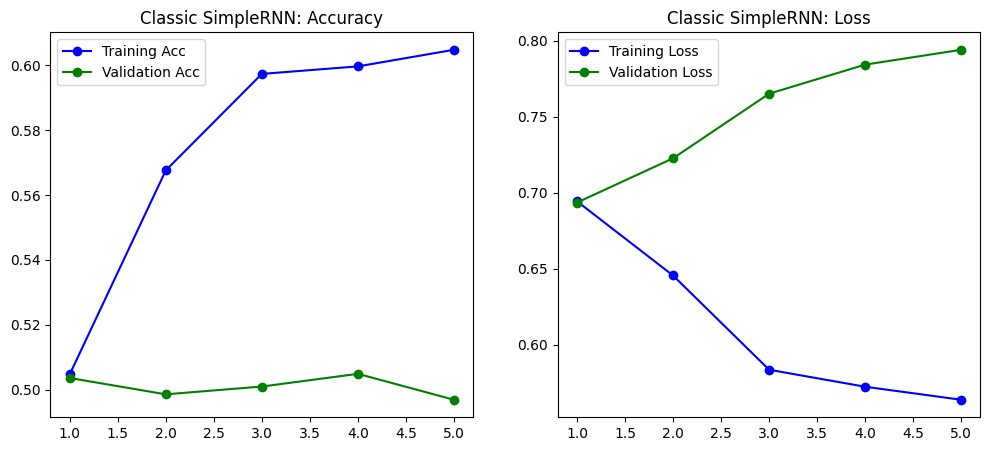

In [ ]:
import matplotlib.pyplot as plt

def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'go-', label='Validation Acc')
    plt.title(f'{model_name}: Accuracy')
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'go-', label='Validation Loss')
    plt.title(f'{model_name}: Loss')
    plt.legend()

    plt.show()

plot_history(history_classic, "Classic SimpleRNN")

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step


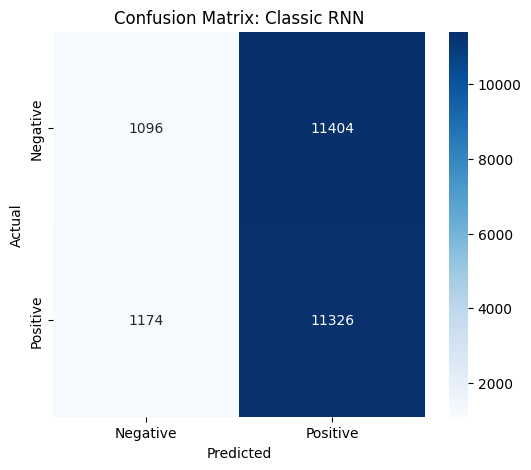


📝 Classification Report:
              precision    recall  f1-score   support

    Negative       0.48      0.09      0.15     12500
    Positive       0.50      0.91      0.64     12500

    accuracy                           0.50     25000
   macro avg       0.49      0.50      0.40     25000
weighted avg       0.49      0.50      0.40     25000



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get predictions (probabilities)
y_pred_probs = model_classic.predict(X_test)
# Convert probabilities to binary (0 or 1)
y_pred = (y_pred_probs > 0.5).astype("int32")

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix: Classic RNN')
plt.show()

# Print Precision, Recall, and F1-score
print("\n📝 Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

In [ ]:
def predict_sentiment(text):
    # 1. Clean the text
    cleaned = clean_text(text)
    # 2. Tokenize and Pad
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')
    # 3. Predict
    prediction = model_classic.predict(padded)[0][0]

    sentiment = "Positive" if prediction > 0.5 else "Negative"
    confidence = prediction if prediction > 0.5 else 1 - prediction

    print(f"Review: {text}")
    print(f"Result: {sentiment} ({confidence*100:.2f}% confidence)\n")

# Try it out!
predict_sentiment("This movie was a absolute masterpiece, I loved every second of it!")
predict_sentiment("The plot was boring and the acting was terrible.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 556ms/step
Review: This movie was a absolute masterpiece, I loved every second of it!
Result: Positive (51.18% confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Review: The plot was boring and the acting was terrible.
Result: Positive (51.18% confidence)



#Advanced Model using an LSTM (Long Short-Term Memory)

In [ ]:
from tensorflow.keras.layers import LSTM, Dropout

# Initialize the Advanced model
model_advanced = Sequential()

# Layer 1: Embedding (SAME as Classic)
model_advanced.add(Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN))

# Layer 2: LSTM (The "Advanced" element)
# We use 64 units (LSTMs can handle more complexity than SimpleRNNs)
# return_sequences=False because we only need the output after the LAST word
model_advanced.add(LSTM(64))

# Layer 3: Dropout
# Randomly sets 50% of neurons to 0 during training to force the network to learn robust features.
model_advanced.add(Dropout(0.5))

# Layer 4: Output (SAME as Classic)
model_advanced.add(Dense(1, activation='sigmoid'))

# Compile
model_advanced.compile(optimizer='adam',
                       loss='binary_crossentropy',
                       metrics=['accuracy'])

model_advanced.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model
history_advanced = model_advanced.fit(
    X_train, y_train,
    epochs=5,  # 5 epochs should be enough to beat the Classic model significantly
    batch_size=32,
    validation_data=(X_test, y_test)
)

print("✅ Advanced Training Complete.")

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - accuracy: 0.5064 - loss: 0.6938 - val_accuracy: 0.5125 - val_loss: 0.6914
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.5391 - loss: 0.6808 - val_accuracy: 0.5280 - val_loss: 0.6756
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.6064 - loss: 0.6191 - val_accuracy: 0.7959 - val_loss: 0.4874
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8297 - loss: 0.4379 - val_accuracy: 0.8352 - val_loss: 0.3977
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8948 - loss: 0.2969 - val_accuracy: 0.8508 - val_loss: 0.3601
✅ Advanced Training Complete.


📊 Advanced Test Loss: 0.3601
🎯 Advanced Test Accuracy: 85.08%


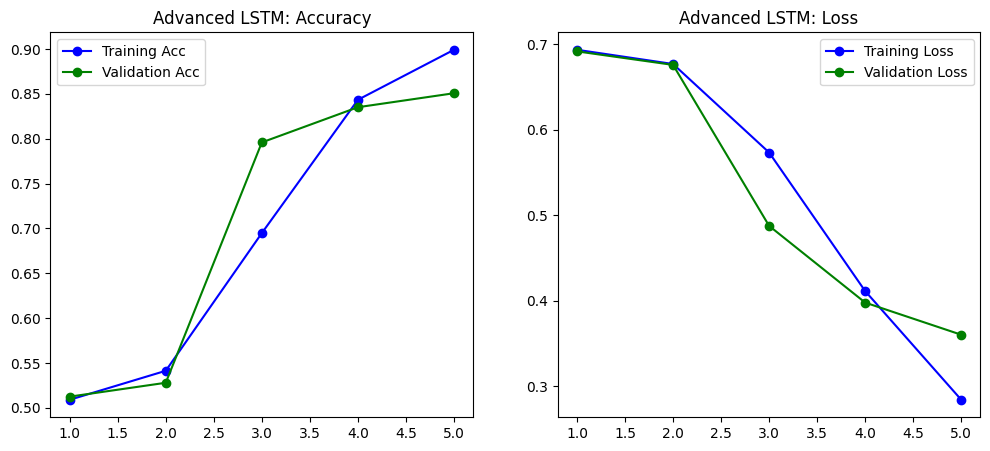

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


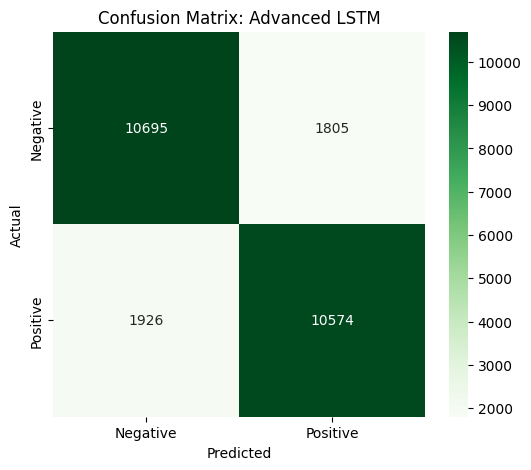


📝 Advanced Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.86      0.85     12500
    Positive       0.85      0.85      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



In [ ]:
# 1. Final Evaluation
results_adv = model_advanced.evaluate(X_test, y_test, verbose=0)
print(f"📊 Advanced Test Loss: {results_adv[0]:.4f}")
print(f"🎯 Advanced Test Accuracy: {results_adv[1]*100:.2f}%")

# 2. Plot History (Using the function we defined earlier)
plot_history(history_advanced, "Advanced LSTM")

# 3. Confusion Matrix & Report
y_pred_probs_adv = model_advanced.predict(X_test)
y_pred_adv = (y_pred_probs_adv > 0.5).astype("int32")

cm_adv = confusion_matrix(y_test, y_pred_adv)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_adv, annot=True, fmt='d', cmap='Greens', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix: Advanced LSTM')
plt.show()

print("\n📝 Advanced Classification Report:")
print(classification_report(y_test, y_pred_adv, target_names=['Negative', 'Positive']))

In [ ]:
def predict_sentiment_advanced(text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')

    prediction = model_advanced.predict(padded)[0][0]

    sentiment = "Positive" if prediction > 0.5 else "Negative"
    confidence = prediction if prediction > 0.5 else 1 - prediction

    print(f"Review: {text}")
    print(f"Result: {sentiment} ({confidence*100:.2f}% confidence)\n")

# Testing the same sentences
predict_sentiment_advanced("This movie was a absolute masterpiece, I loved every second of it!")
predict_sentiment_advanced("The plot was boring and the acting was terrible.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Review: This movie was a absolute masterpiece, I loved every second of it!
Result: Positive (84.12% confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Review: The plot was boring and the acting was terrible.
Result: Negative (97.56% confidence)

